In [4]:
import numpy as np
from tqdm import tqdm
from Dataflux.pytorch.dataset import Dataset


dataset = Dataset("thyssen-vd2-labeled-trainset", 50, 50, 1, 50)
result = {key: [] for key in dataset.get_args().names}

for ins, out in tqdm(dataset):
    for i, key in enumerate(dataset.get_args().names):
        result[key] += list(ins[:, i])

for key in dataset.get_args().names:
    result[key] = np.array(result[key])

100%|██████████| 102868/102868 [01:46<00:00, 969.07it/s]


array([[<Axes: title={'center': 'Biomethandurchfluss (m^3/min)'}>,
        <Axes: title={'center': 'DifferenzdruckTriebwerksölPDIT74553 (bar)'}>,
        <Axes: title={'center': 'EnddruckErsteStufePIT74339 (bar)'}>,
        <Axes: title={'center': 'EnddruckZweiteStufePIT74397 (bar)'}>,
        <Axes: title={'center': 'EndtemperaturErsteStufeTETIT74334 (°C)'}>],
       [<Axes: title={'center': 'EndtemperaturZweiteStufeTETIT74371 (°C)'}>,
        <Axes: title={'center': 'EndtemperaturZweiteStufenachKühlerTETIT74378 (°C)'}>,
        <Axes: title={'center': 'KompressordrehzahlSE74201 (rpm)'}>,
        <Axes: title={'center': 'KühlwasserdrucknachPumpePIT74425 (bar)'}>,
        <Axes: title={'center': 'KühlwasserdurchflussmengeFIT74423 (m^3/min)'}>],
       [<Axes: title={'center': 'KühlwassertemperaturnachKühlerTETIT74422 (°C)'}>,
        <Axes: title={'center': 'Motorlager (°C)'}>,
        <Axes: title={'center': 'PackungsleckageFIT74389 (Nm3h)'}>,
        <Axes: title={'center': 'Saugdruc

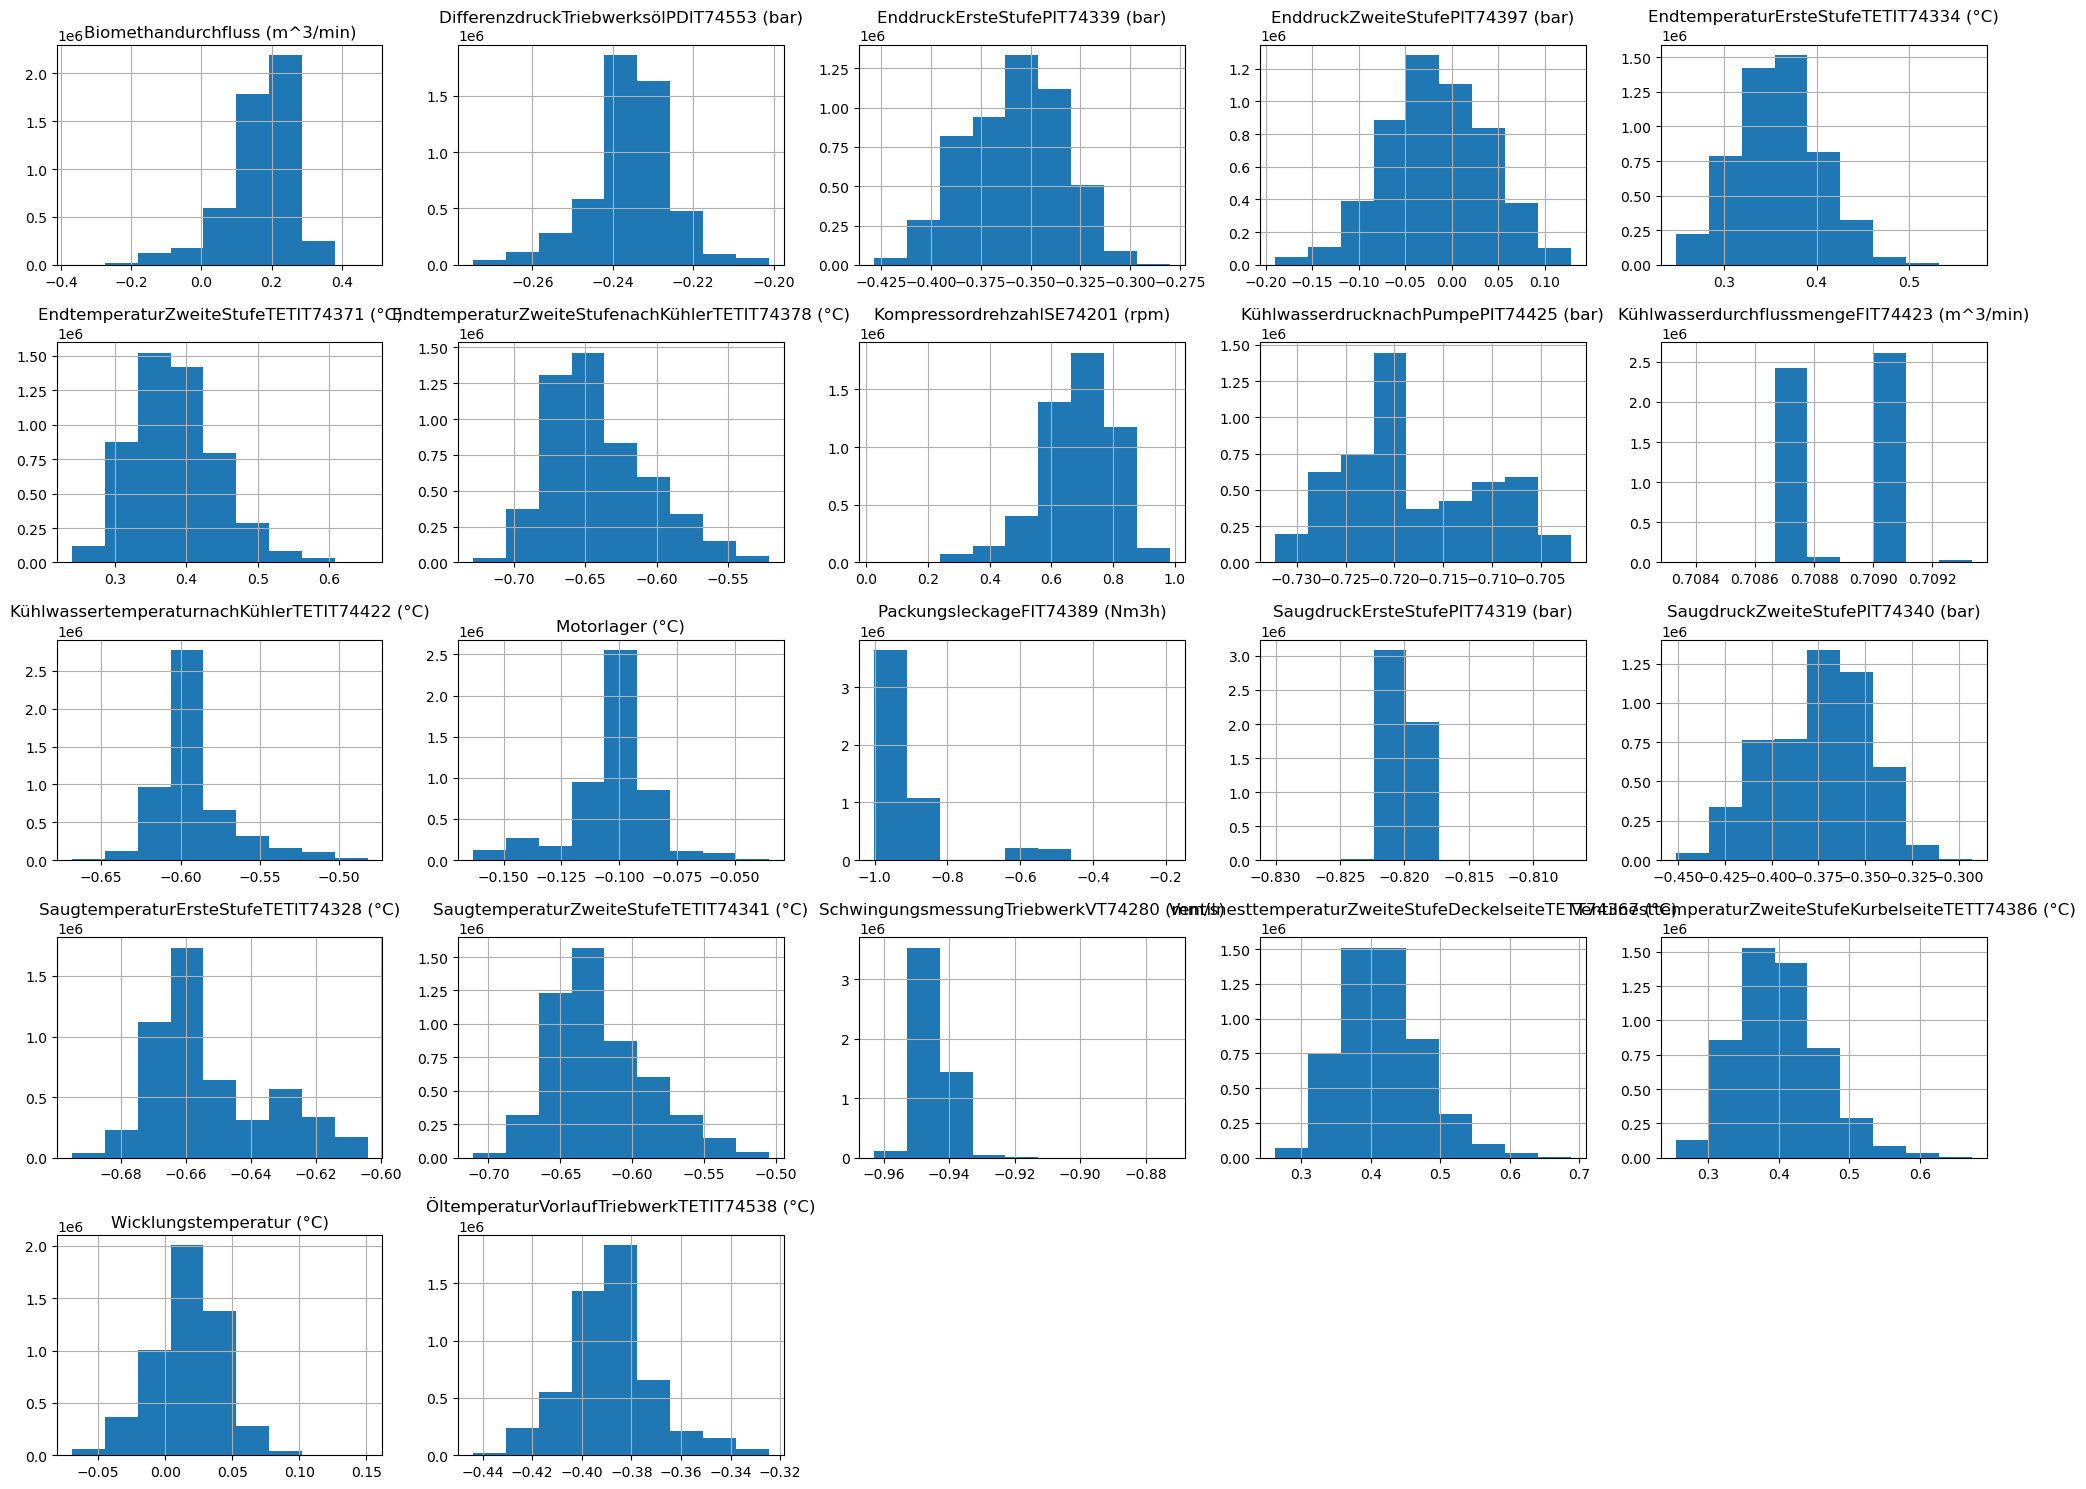

In [7]:
from pandas import DataFrame

df = DataFrame(result)
df.hist(bins=9, figsize=(20, 15))

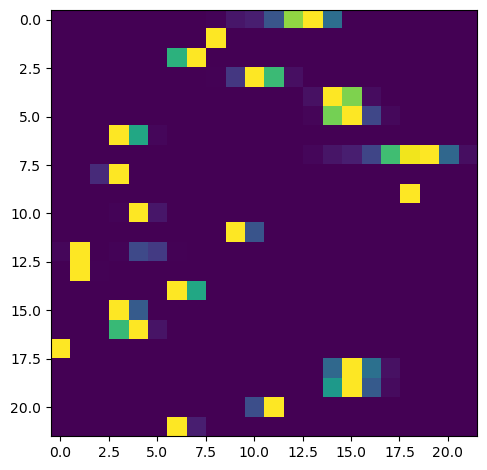

<BarContainer object of 22 artists>

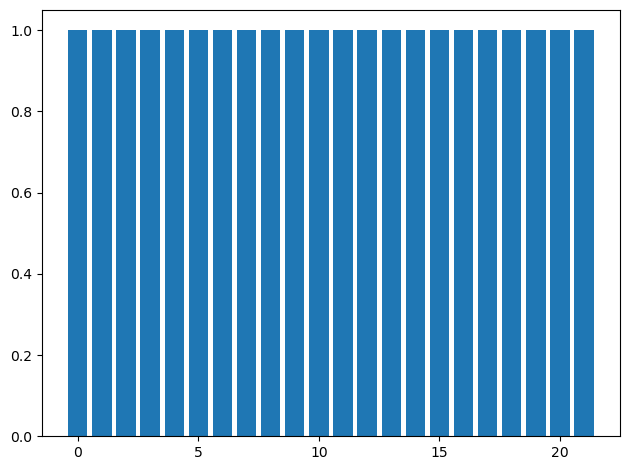

In [42]:
import matplotlib.pyplot as plt

image = []
for key, value in result.items():
    bins = np.histogram(value, bins=len(result))
    bins = bins[0] / max(bins[0])
    image.append(bins)

image = np.array(image, dtype=np.float32)
plt.imshow(image)
plt.show()
plt.bar(np.arange(0, 22), image.max(axis=1))

In [40]:
for row in image.tolist():
    ",".join(list(row))

TypeError: sequence item 0: expected str instance, float found

In [41]:
str(image.tolist())

'[[0.0003537538868840784, 0.0005208536749705672, 0.0015812264755368233, 0.002675374737009406, 0.015410514548420906, 0.0369735024869442, 0.05135919526219368, 0.06386146694421768, 0.055174048990011215, 0.08273041248321533, 0.16431424021720886, 0.2573097348213196, 0.4460863173007965, 0.7024405598640442, 0.8055357933044434, 0.5925999879837036, 1.0, 0.2895715534687042, 0.0026824853848665953, 0.00014043496048543602, 0.0001768769434420392, 0.00010399297752883285], [0.007494788151234388, 0.022451311349868774, 0.06425048410892487, 0.02817539870738983, 0.060255784541368484, 0.15671531856060028, 0.13411173224449158, 0.15979871153831482, 0.22946399450302124, 0.5155420303344727, 0.777367353439331, 0.9975552558898926, 1.0, 0.8038098216056824, 0.4985775351524353, 0.29860398173332214, 0.11594551801681519, 0.05001994967460632, 0.05195237696170807, 0.04987829551100731, 0.04295603185892105, 0.006690890062600374], [0.008323028683662415, 0.05143539234995842, 0.08411009609699249, 0.1422409564256668, 0.32021